## Step 1: Import the Libraries
The libraries are used to handle data, create graphs, build the ANN model, and evaluate its performance.

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

## Step 2: Load the Dataset
Load the Diabetes dataset from Scikit-learn. Separate the input features (X) and the target values (y).

In [41]:
diabetes = load_diabetes()

X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = diabetes.target

print(X.head())
print("Shape of dataset:", X.shape)

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  
Shape of dataset: (442, 10)


## Step 3: Check Missing Values
Check whether the dataset contains missing values. If any are found in the features, replace them with the median of the respective columns.

In [42]:
print(X.isnull().sum())
print("Missing values in target:", np.isnan(y).sum())

X = X.fillna(X.median())

age    0
sex    0
bmi    0
bp     0
s1     0
s2     0
s3     0
s4     0
s5     0
s6     0
dtype: int64
Missing values in target: 0


## Step 4: Explore the Dataset
Display basic information and statistical details to understand the dataset and its features.

In [43]:
df = X.copy()
df["target"] = y

print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB
None
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.

## Step 5: Visualize Feature Distributions
Histograms help us understand how the values of each input feature are distributed.

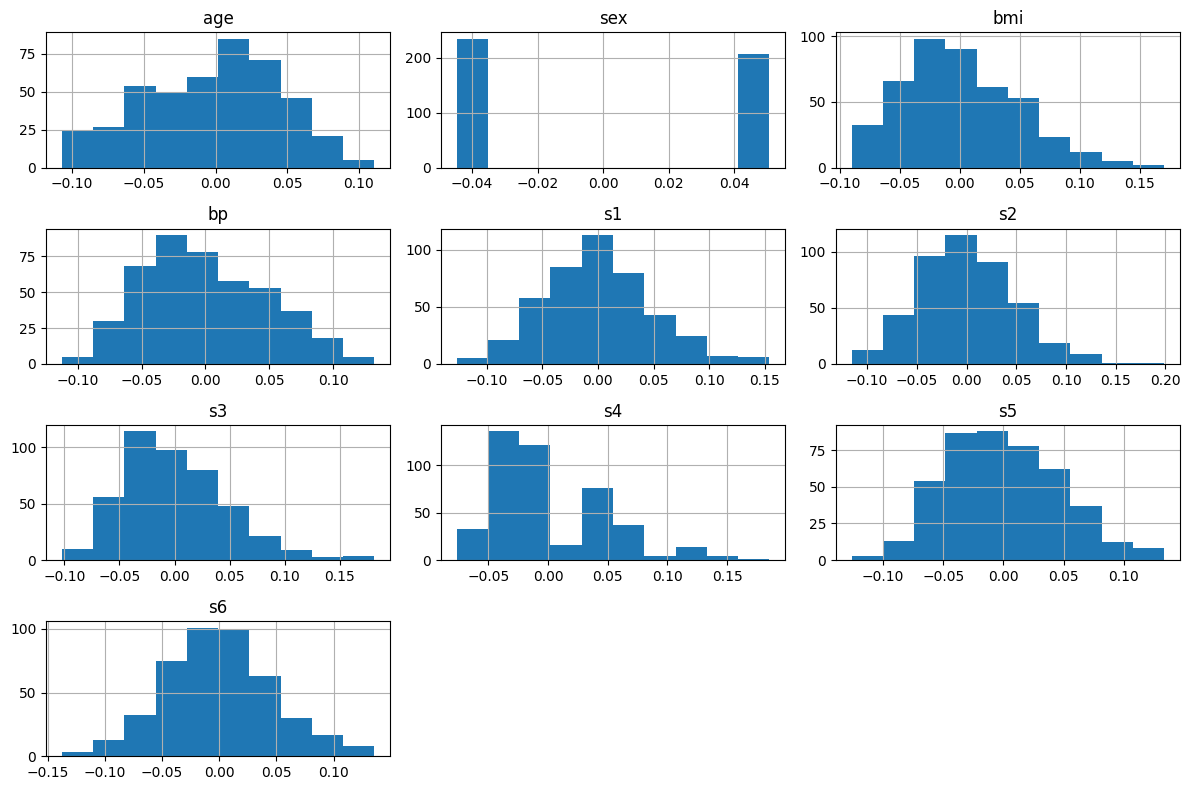

In [44]:
X.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

## Step 6: Visualize the Target Distribution
This histogram shows how the diabetes progression target values are distributed across the dataset.

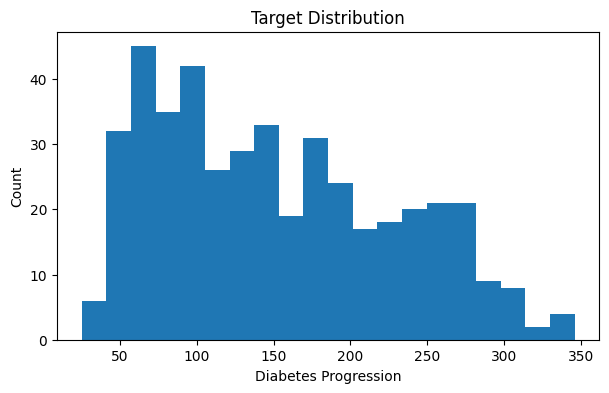

In [45]:
plt.figure(figsize=(7, 4))
plt.hist(y, bins=20)
plt.xlabel("Diabetes Progression")
plt.ylabel("Count")
plt.title("Target Distribution")
plt.show()

## Step 7: Correlation Heatmap
A correlation heatmap helps us understand the relationships between the features and the target variable.

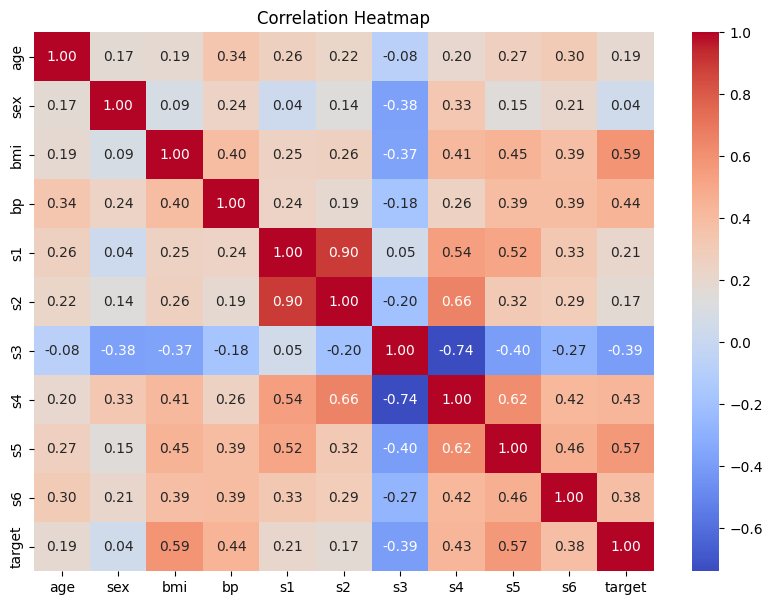

In [46]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## Step 8: Split the Dataset
Split the data into training and testing sets. The model learns from the training data and is evaluated using the testing data.

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (353, 10)
Testing data: (89, 10)


## Step 9: Normalize the Features
StandardScaler standardizes the input features so that they have comparable scales. The scaler is fitted only on the training data.

In [48]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Step 10: Build the ANN Model
Create an Artificial Neural Network with two hidden layers and one output neuron. ReLU is used in the hidden layers, and the output predicts a continuous numerical value.

In [49]:
model = Sequential()

model.add(tf.keras.Input(shape=(10,)))
model.add(Dense(64, activation="relu"))
model.add(Dense(32, activation="relu"))
model.add(Dense(1))

model.compile(optimizer="adam", loss="mse")

model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_25 (Dense)                │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

## Step 11: Train the Model
Train the ANN using the training data for 100 epochs. A portion of the training data is used for validation.

In [50]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2
)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 31344.6914 - val_loss: 22160.3730
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30900.3945 - val_loss: 21779.8574
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30253.1211 - val_loss: 21218.7715
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 29282.0332 - val_loss: 20359.1660
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 27779.8105 - val_loss: 19158.3887
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 25704.5957 - val_loss: 17538.2598
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 22937.2695 - val_loss: 15519.7109
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 19520.9062 - val_loss: 13219.1025
Epoch 9/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 16041.3223 - val_loss: 10739.4756
Epoch 10/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 12525.4795 - val_loss: 8605.0439
Epoch 11/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 9844.5723

## Step 12: Visualize Training Loss
Plot the training and validation loss to observe how the model learns during training.

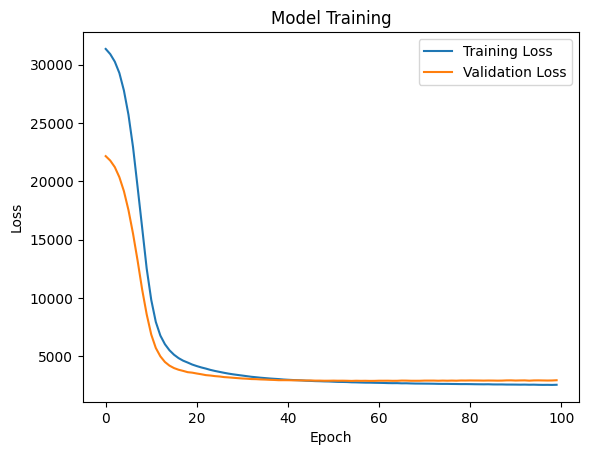

In [51]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Training")
plt.legend()
plt.show()

## Step 13: Evaluate the Model
Use the test data to make predictions. Calculate Mean Squared Error (MSE) and R² score to evaluate the model's performance.

In [52]:
y_pred = model.predict(X_test).flatten()

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("R2 Score:", r2)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Mean Squared Error: 2840.5180580522124
R2 Score: 0.46386623243709235


## Step 14: Improve the Model
Build another ANN with more hidden layers and neurons to experiment with a different architecture.

In [53]:



model2 = Sequential()

model2.add(tf.keras.Input(shape=(10,)))
model2.add(Dense(128, activation="relu"))
model2.add(Dense(64, activation="relu"))
model2.add(Dense(32, activation="relu"))
model2.add(Dense(1))

model2.compile(optimizer="adam", loss="mse")

history2 = model2.fit(
    X_train,
    y_train,
    epochs=150,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)


## Step 15: Evaluate the Improved Model
Evaluate the second model using the same test data and metrics so its performance can be compared fairly with the original model.

In [54]:
y_pred2 = model2.predict(X_test).flatten()

mse2 = mean_squared_error(y_test, y_pred2)
r2_2 = r2_score(y_test, y_pred2)

print("Original Model MSE:", mse)
print("Improved Model MSE:", mse2)

print("Original Model R2:", r2)
print("Improved Model R2:", r2_2)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Original Model MSE: 2840.5180580522124
Improved Model MSE: 2936.5896913090446
Original Model R2: 0.46386623243709235
Improved Model R2: 0.44573318570362896


## Step 16: Compare Both Models
Create a table to compare the MSE and R² scores of the original and improved models.

In [55]:
results = pd.DataFrame({
    "Model": ["Original ANN", "Improved ANN"],
    "MSE": [mse, mse2],
    "R2 Score": [r2, r2_2]
})

print(results)

          Model          MSE  R2 Score
0  Original ANN  2840.518058  0.463866
1  Improved ANN  2936.589691  0.445733


## Step 17: Conclusion

In this assignment, I used the Diabetes dataset from Scikit-learn to predict diabetes progression. I checked for missing values, explored the dataset using graphs, and normalized the input features. I built an ANN model using TensorFlow and evaluated its performance using Mean Squared Error (MSE) and R² score. I also tried a second model with more hidden layers and neurons and compared its performance with the original model.

The Original ANN achieved an MSE of 2840.52 and an R² score of 0.4639, while the Improved ANN achieved an MSE of 2936.59 and an R² score of 0.4457. The Original ANN performed better because it had a lower MSE and a higher R² score. This experiment showed that adding more hidden layers and neurons does not always improve model performance.